<a href="https://colab.research.google.com/github/arsyaxyz/portofolio/blob/main/E_Commerce_Product_Review_Sentiment_%26_Complaint_Analyzer_(Fine_Tuned_IndoBERT).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import os
import pandas as pd

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Path langsung ke folder 'dataset' -> file 'PRDECT-ID Dataset.csv'
csv_path = '/content/drive/MyDrive/dataset/PRDECT-ID Dataset.csv'

# Backup otomatis kalau folder 'dataset' kamu pakai huruf besar 'Dataset'
if not os.path.exists(csv_path):
    alt_path = '/content/drive/MyDrive/Dataset/PRDECT-ID Dataset.csv'
    if os.path.exists(alt_path):
        csv_path = alt_path

# 3. Baca dataset
print(f"✅ Membaca file dari: {csv_path}")
df = pd.read_csv(csv_path)

print(f"Total baris: {len(df)} | Total kolom: {len(df.columns)}")
df[['Product Name', 'Customer Review', 'Overall Rating', 'Sentiment', 'Emotion']].head()

Mounted at /content/drive
✅ Membaca file dari: /content/drive/MyDrive/Dataset/PRDECT-ID Dataset.csv
Total baris: 5400 | Total kolom: 11


,Product Name,Customer Review,Overall Rating,Sentiment,Emotion
0,Wireless Keyboard i8 Mini TouchPad Mouse 2.4G ...,Alhamdulillah berfungsi dengan baik. Packaging...,4.9,Positive,Happy
1,PAKET LISENSI WINDOWS 10 PRO DAN OFFICE 2019 O...,"barang bagus dan respon cepat, harga bersaing ...",4.9,Positive,Happy
2,SSD Midasforce 128 Gb - Tanpa Caddy,"barang bagus, berfungsi dengan baik, seler ram...",5.0,Positive,Happy
3,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,bagus sesuai harapan penjual nya juga ramah. t...,4.7,Positive,Happy
4,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,"Barang Bagus, pengemasan Aman, dapat Berfungsi...",4.7,Positive,Happy


In [2]:
import re

# 1. Cek dulu nama kolom rating pelanggan & distribusinya
print("Daftar lengkap 11 kolom:", list(df.columns))

# Gunakan 'Customer Rating' jika ada, jika namanya berbeda otomatis terdeteksi
rating_col = 'Customer Rating' if 'Customer Rating' in df.columns else [c for c in df.columns if 'Rating' in c and c != 'Overall Rating'][0]
print(f"\nDistribusi Bintang Asli Pembeli ({rating_col}):")
print(df[rating_col].value_counts().sort_index())

# 2. Kamus normalisasi kata gaul/singkatan khas e-commerce
slang_dict = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "tdk": "tidak", "gada": "tidak ada",
    "bgt": "banget", "bngt": "banget", "brg": "barang", "brng": "barang",
    "mantul": "mantap betul", "ori": "original", "cpt": "cepat", "lmyn": "lumayan",
    "recomended": "recommended", "hrg": "harga", "mksh": "terima kasih", "tq": "terima kasih",
    "yg": "yang", "dgn": "dengan", "tp": "tapi", "tpi": "tapi", "krn": "karena",
    "udh": "sudah", "sdh": "sudah", "blm": "belum", "bgs": "bagus", "ancur": "hancur"
}

def clean_review(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)        # Hapus link
    text = re.sub(r'[^a-zA-Z0-9\s.,!?]', ' ', text)   # Bersihkan simbol aneh
    text = re.sub(r'(.)\1{2,}', r'\1', text)          # Huruf berulang ('bagusss' -> 'bagus')
    words = [slang_dict.get(w, w) for w in text.split()]
    return " ".join(words)

# 3. Mapping 3 kelas Sentimen dari Bintang Pembeli (1-2: Negatif, 3: Netral, 4-5: Positif)
def map_3_class(row):
    rating = row[rating_col]
    if rating <= 2:
        return 0  # Negatif
    elif rating == 3:
        return 1  # Netral
    else:
        return 2  # Positif

df['clean_text'] = df['Customer Review'].apply(clean_review)
df['label'] = df.apply(map_3_class, axis=1)

# Bersihkan baris kosong atau duplikat
df_clean = df[['clean_text', 'label', rating_col, 'Sentiment', 'Emotion']].dropna().drop_duplicates(subset=['clean_text'])

print("\n✅ Distribusi 3 Kelas Sentimen (Siap Masuk IndoBERT):")
print(df_clean['label'].map({0: '0 - Negatif', 1: '1 - Netral', 2: '2 - Positif'}).value_counts())

Daftar lengkap 11 kolom: ['Category', 'Product Name', 'Location', 'Price', 'Overall Rating', 'Number Sold', 'Total Review', 'Customer Rating', 'Customer Review', 'Sentiment', 'Emotion']

Distribusi Bintang Asli Pembeli (Customer Rating):
Customer Rating
1    1832
2     561
3     462
4     395
5    2150
Name: count, dtype: int64

✅ Distribusi 3 Kelas Sentimen (Siap Masuk IndoBERT):
label
2 - Positif    2499
0 - Negatif    2317
1 - Netral      459
Name: count, dtype: int64


In [3]:
!pip install -q transformers datasets accelerate scikit-learn

import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

# 1. Split Train (80%), Validation (10%), Test (10%) secara proporsional (stratified)
train_df, temp_df = train_test_split(df_clean, test_size=0.2, stratify=df_clean['label'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['label'], random_state=42)

# 2. Oversampling kelas Netral (label == 1) HANYA di data Train (3x lipat) agar seimbang
netral_train = train_df[train_df['label'] == 1]
train_df_balanced = pd.concat([train_df, netral_train, netral_train], ignore_index=True).sample(frac=1, random_state=42)

print("Distribusi Data Train Setelah Oversampling Netral:")
print(train_df_balanced['label'].value_counts())

# Hitung Class Weights untuk sisa perbedaan jumlah data
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df_balanced['label']),
    y=train_df_balanced['label'].values
)
device = "cuda" if torch.cuda.is_available() else "cpu"
weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
print(f"\nMenggunakan device: {device.upper()} | Bobot Kelas: {np.round(class_weights, 3)}")

# 3. Tokenisasi dengan IndoBERT
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    return tokenizer(batch["clean_text"], padding="max_length", truncation=True, max_length=128)

train_ds = Dataset.from_pandas(train_df_balanced[['clean_text', 'label']].reset_index(drop=True)).map(tokenize_fn, batched=True)
val_ds = Dataset.from_pandas(val_df[['clean_text', 'label']].reset_index(drop=True)).map(tokenize_fn, batched=True)
test_ds = Dataset.from_pandas(test_df[['clean_text', 'label']].reset_index(drop=True)).map(tokenize_fn, batched=True)

# 4. Load Model IndoBERT (3 Kelas)
id2label = {0: "Negatif", 1: "Netral", 2: "Positif"}
label2id = {"Negatif": 0, "Netral": 1, "Positif": 2}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=3, id2label=id2label, label2id=label2id
)

# 5. Custom Trainer dengan Weighted Loss
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "f1_weighted": f1_score(labels, preds, average="weighted")
    }

# 6. Konfigurasi & Mulai Training (Sekitar 3-4 menit di T4 GPU)
training_args = TrainingArguments(
    output_dir="./checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    fp16=torch.cuda.is_available(),
    report_to="none"
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

trainer.train()

Distribusi Data Train Setelah Oversampling Netral:
label
2    1999
0    1854
1    1101
Name: count, dtype: int64

Menggunakan device: CUDA | Bobot Kelas: [0.891 1.5   0.826]


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1240, training_loss=0.1904531078953897, metrics={'train_runtime': 222.3621, 'train_samples_per_second': 89.116, 'train_steps_per_second': 5.576, 'total_flos': 1303463871424512.0, 'train_loss': 0.1904531078953897, 'epoch': 4.0})

=== HASIL EVALUASI DATA TEST ) ===
              precision    recall  f1-score   support

     Negatif     0.8523    0.8707    0.8614       232
      Netral     0.2558    0.2391    0.2472        46
     Positif     0.9718    0.9640    0.9679       250

    accuracy                         0.8598       528
   macro avg     0.6933    0.6913    0.6922       528
weighted avg     0.8569    0.8598    0.8583       528



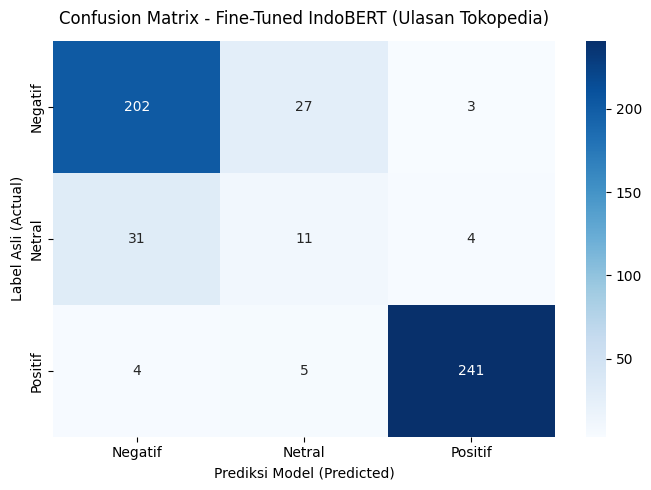

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✅ Model & Tokenizer berhasil disimpan permanen di: /content/drive/MyDrive/Dataset/indobert_prdect_model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


=== UJI COBA PREDIKSI ULASAN BARU ===
Ulasan  : Barang ori mantul bgt, pengiriman super kilat paking aman bubble wrap tebel!
Prediksi: Positif (100.0%) | Detail: [Positif: 100.0%, Negatif: 0.0%, Netral: 0.0%]

Ulasan  : Sebenernya bahannya lumayan oke sih buat harga segini, cuma pengirimannya aja agak lama.
Prediksi: Netral (98.5%) | Detail: [Netral: 98.5%, Positif: 1.5%, Negatif: 0.0%]

Ulasan  : Kecewa berat! Pesen warna hitam yang dikirim malah rusak, gak bisa dipakai sama sekali.
Prediksi: Negatif (99.9%) | Detail: [Negatif: 99.9%, Positif: 0.1%, Netral: 0.0%]



In [5]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from transformers import pipeline

# 1. Evaluasi pada Data Test Murni
preds_output = trainer.predict(test_ds)
y_preds = np.argmax(preds_output.predictions, axis=-1)
target_names = ["Negatif", "Netral", "Positif"]

print("=== HASIL EVALUASI DATA TEST ) ===")
print(classification_report(test_df['label'], y_preds, target_names=target_names, digits=4))

# 2. Buat Visualisasi Confusion Matrix
cm = confusion_matrix(test_df['label'], y_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - Fine-Tuned IndoBERT (Ulasan Tokopedia)', fontsize=12, pad=12)
plt.ylabel('Label Asli (Actual)')
plt.xlabel('Prediksi Model (Predicted)')
plt.tight_layout()
plt.savefig('confusion_matrix_upwork.png', dpi=300)
plt.show()

# 3. Simpan Model & Tokenizer ke folder Dataset di Google Drive kamu
folder_dataset = os.path.dirname(csv_path)
save_dir = os.path.join(folder_dataset, "indobert_prdect_model")

trainer.save_model(save_dir)
tokenizer.save_pretrained(save_dir)
print(f"\n✅ Model & Tokenizer berhasil disimpan permanen di: {save_dir}")

# 4. Tes Prediksi Real-Time dengan Kalimat Ulasan E-Commerce
clf = pipeline("text-classification", model=save_dir, tokenizer=save_dir, top_k=None, device=0 if torch.cuda.is_available() else -1)

contoh_ulasan = [
    "Barang ori mantul bgt, pengiriman super kilat paking aman bubble wrap tebel!",
    "Sebenernya bahannya lumayan oke sih buat harga segini, cuma pengirimannya aja agak lama.",
    "Kecewa berat! Pesen warna hitam yang dikirim malah rusak, gak bisa dipakai sama sekali."
]

print("\n=== UJI COBA PREDIKSI ULASAN BARU ===")
for teks in contoh_ulasan:
    hasil_semua = sorted(clf(clean_review(teks))[0], key=lambda x: x['score'], reverse=True)
    top = hasil_semua[0]
    rincian = ", ".join([f"{h['label']}: {h['score']*100:.1f}%" for h in hasil_semua])
    print(f"Ulasan  : {teks}")
    print(f"Prediksi: {top['label']} ({top['score']*100:.1f}%) | Detail: [{rincian}]\n")

In [7]:
!pip install -q gradio plotly

import gradio as gr
import pandas as pd
import plotly.express as px
import torch
from transformers import pipeline

# 1. Load model dari Google Drive yang sudah disimpan di Cell 4
device_id = 0 if torch.cuda.is_available() else -1
clf = pipeline("text-classification", model=save_dir, tokenizer=save_dir, top_k=None, device=device_id)

# --- FUNGSI 1: Analisis Ulasan Tunggal (Real-Time) ---
def predict_single_review(review_text):
    if not str(review_text).strip():
        return {"Kosong": 1.0}, "Silakan masukkan teks ulasan terlebih dahulu."

    cleaned = clean_review(review_text)
    scores = clf(cleaned)[0]

    # Format dictionary untuk Bar Confidence Gradio
    prob_dict = {item['label']: float(item['score']) for item in scores}
    top = sorted(scores, key=lambda x: x['score'], reverse=True)[0]

    badge_color = {"Positif": "🟢 POSITIF", "Netral": "🟡 NETRAL", "Negatif": "🔴 NEGATIF (KOMPLAIN)"}
    ringkasan = f"### Keputusan Model: {badge_color.get(top['label'], top['label'])} (Confidence: {top['score']*100:.1f}%)\n"
    ringkasan += f"**Teks setelah normalisasi slang:** *\"{cleaned}\"*"

    return prob_dict, ringkasan

# --- FUNGSI 2: Dashboard Massal dari Dataset / Upload CSV ---
def analyze_batch_data(file_obj, jumlah_sampel):
    if file_obj is not None:
        df_batch = pd.read_csv(file_obj.name)
        col_text = 'Customer Review' if 'Customer Review' in df_batch.columns else df_batch.columns[0]
    else:
        # Jika tidak upload file, gunakan sampel dari dataset PRDECT-ID yang sedang dibuka
        df_batch = df.sample(n=int(jumlah_sampel), random_state=42).copy()
        col_text = 'Customer Review'

    df_batch = df_batch.dropna(subset=[col_text]).head(int(jumlah_sampel))
    texts_clean = [clean_review(t) for t in df_batch[col_text].tolist()]

    preds = clf(texts_clean)

    sentiments = []
    confidences = []
    for p in preds:
        top = sorted(p, key=lambda x: x['score'], reverse=True)[0]
        sentiments.append(top['label'])
        confidences.append(round(top['score'] * 100, 1))

    df_result = pd.DataFrame({
        "Ulasan Pembeli": df_batch[col_text].values,
        "Sentimen": sentiments,
        "Confidence (%)": confidences
    })

    # Hitung KPI
    total = len(df_result)
    pos = (df_result['Sentimen'] == 'Positif').sum()
    net = (df_result['Sentimen'] == 'Netral').sum()
    neg = (df_result['Sentimen'] == 'Negatif').sum()

    kpi_markdown = f"""
    | 📊 Total Ulasan Dianalisis | 🟢 Sentimen Positif | 🟡 Sentimen Netral | 🔴 Sentimen Negatif (Prioritas Admin) |
    | :---: | :---: | :---: | :---: |
    | **{total} Ulasan** | **{pos} ({pos/total*100:.1f}%)** | **{net} ({net/total*100:.1f}%)** | **{neg} ({neg/total*100:.1f}%)** |
    """

    # Buat Grafik Donut Proporsi Sentimen
    fig_pie = px.pie(
        df_result, names="Sentimen", title="Proporsi Sentimen Pelanggan E-Commerce", hole=0.45,
        color="Sentimen", color_discrete_map={"Positif": "#22c55e", "Netral": "#eab308", "Negatif": "#ef4444"}
    )

    # Urutkan tabel agar komplain (Negatif) muncul paling atas untuk ditindaklanjuti
    df_complaints = df_result.sort_values(by=["Sentimen", "Confidence (%)"], ascending=[True, False])

    return kpi_markdown, fig_pie, df_complaints

# --- TAMPILAN UI DASHBOARD ---
with gr.Blocks(theme=gr.themes.Soft(), title="E-Commerce Sentiment Dashboard") as demo:
    gr.Markdown(
        """
        # 🛒 Indonesian E-Commerce Product Review Sentiment Dashboard
        **Powered by Fine-Tuned IndoBERT (`indobenchmark/indobert-base-p1`)** | Klasifikasi Otomatis: **Positif, Netral, & Negatif**
        """
    )

    with gr.Tabs():
        # TAB 1: LIVE PLAYGROUND
        with gr.TabItem("⚡ Live Review Tester"):
            with gr.Row():
                with gr.Column(scale=1):
                    input_text = gr.Textbox(
                        label="Masukkan Ulasan Produk (Tokopedia / Shopee)",
                        placeholder="Ketik ulasan dengan bahasa gaul/singkatan di sini...",
                        lines=4,
                        value="Sebenernya bahannya lumayan adem sih buat harga segini, cuma pengirimannya aja agak lama."
                    )
                    btn_predict = gr.Button("🔍 Analisis Sentimen Sekarang", variant="primary")
                    gr.Examples(
                        examples=[
                            ["Barang ori mantul bgt, pengiriman super kilat paking aman bubble wrap tebel!"],
                            ["Sebenernya bahannya lumayan oke sih buat harga segini, cuma jahitan agak kurang rapi dikit."],
                            ["Kecewa berat! Pesen warna hitam yang dikirim malah rusak, gak bisa dipakai sama sekali."]
                        ],
                        inputs=input_text,
                        label="Contoh Ulasan (Klik untuk tes cepat):"
                    )
                with gr.Column(scale=1):
                    output_summary = gr.Markdown(label="Ringkasan Keputusan")
                    output_probs = gr.Label(num_top_classes=3, label="Distribusi Probabilitas Kelas")

            btn_predict.click(fn=predict_single_review, inputs=input_text, outputs=[output_probs, output_summary])

        # TAB 2: BATCH DASHBOARD ANALYTICS
        with gr.TabItem("📊 Store Analytics Dashboard (Batch CSV)"):
            with gr.Row():
                file_input = gr.File(label="Upload CSV Ulasan Toko", file_types=[".csv"])
                sample_slider = gr.Slider(minimum=20, maximum=200, value=100, step=20, label="Jumlah Sampel Ulasan yang Dianalisis")
                btn_batch = gr.Button("🚀 Generate Dashboard Analitik", variant="primary")

            kpi_out = gr.Markdown()
            with gr.Row():
                plot_out = gr.Plot(label="Visualisasi Sentimen")
                table_out = gr.Dataframe(label="Daftar Ulasan & Prioritas Komplain", wrap=True)

            btn_batch.click(fn=analyze_batch_data, inputs=[file_input, sample_slider], outputs=[kpi_out, plot_out, table_out])

# Jalankan dan buat link publik yang bisa dibuka di browser luar
demo.launch(share=True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

/tmp/ipykernel_1434/1755788404.py:83: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="E-Commerce Sentiment Dashboard") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://73e6f545eab816b052.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
